# Machine Learning
Predizione di quali creators potrebbero fare una collaborazione.
Per farlo verrà creato prima il Dataset, utilizzando i dati ottenuti nelle fasi precedenti della ricerca, del quale ogni record sarà strutturato:
- Creator1
- Creator2
- JaccardSimilarity Coefficient
- Adamic Adar
- Preferential Attachment
- hasCollab

I campi "JaccardSimilarityCoefficient", "AdicAdar" e "PreferentialAttachment" sono le features(X) mentre il campo "hasCollab" equivale al Target (y)

### Librerie Utilizzate

In [1]:
import json
import pandas as pd
import numpy as np

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
# from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score, confusion_matrix, precision_recall_curve, roc_curve, roc_auc_score, ConfusionMatrixDisplay, PrecisionRecallDisplay

import matplotlib.pyplot as plt

## Creazione del Dataset

In [2]:
# Dal file .json ottenuto nella fase di Data Gathering con struttura { nodo : { nodoConnesso : occorrenzePeso } }
# Collaborazioni totali trovate
with open('Data/collab_network.json', 'r') as f:
    collab = json.load(f)
    
# Dal file .json ottenuto nell'analisi della Similarità con Jaccard con struttura { "creator1 ; creator2" : JaccardSimilarity_Coefficient} }
with open('Data/similarity.json', 'r') as f:
    similarity = json.load(f)

In [3]:
# Funzione che verifica se due Creators in Input hanno collaborato
def hasCollab(creator1, creator2):
    
    for c1, c2 in collab.items():
        
        if c1 == creator1 and creator2 in c2: return 1
        if c1 == creator2 and creator1 in c2: return 1
        
       
    return 0
    

In [4]:
# Creazione del Dataset
data = []

# i = 0
for creators, similarities in similarity.items():
    
    creator1, creator2 = creators.split(' ; ')
    
    # Verifico se i due Creators hanno collaborato
    has_collab = hasCollab(creator1, creator2)

    data.append({
        'creator1': creator1,
        'creator2': creator2,
        'Jaccard': similarities[0],
        'AdamicAdar' : similarities[1],
        'PrAttachment' : similarities[2],
        'Resource' : similarities[3],
        'hasCollab': has_collab
    })
    
    # Stampo record per debug e verifica che stia eseguendo qualcosa
    # print(f"[{i}] record aggiunto: {creator1} ; {creator2} ; {jaccard_similarity:.4f} ; {has_collab}")
    
    # i += 1

# Creo il Dataframe
df = pd.DataFrame(data)

# Salvo in formato CSV
df.to_csv('Data/MLdataset.csv', index=False)

print(df.head(10))

  creator1          creator2  Jaccard  AdamicAdar  PrAttachment  Resource  \
0  ysterik               BBC      0.0         0.0             0       0.0   
1  ysterik         OnsOranje      0.0         0.0             0       0.0   
2  ysterik     rolandpollard      0.0         0.0             0       0.0   
3  ysterik     ambraofficial      0.0         0.0             0       0.0   
4  ysterik          nyknicks      0.0         0.0             0       0.0   
5  ysterik        CallofDuty      0.0         0.0             0       0.0   
6  ysterik          pledis17      0.0         0.0             0       0.0   
7  ysterik  Pokemonufficiale      0.0         0.0             0       0.0   
8  ysterik          MemGrizz      0.0         0.0             0       0.0   
9  ysterik              grax      0.0         0.0             0       0.0   

   hasCollab  
0          0  
1          0  
2          0  
3          0  
4          0  
5          0  
6          0  
7          0  
8          0  
9 

In [5]:
# Carico e visualizzo le info del Dataset
data = pd.read_csv("Data/MLdataset.csv")

# Creo il Dataframe
df = pd.DataFrame(data)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2118711 entries, 0 to 2118710
Data columns (total 7 columns):
 #   Column        Dtype  
---  ------        -----  
 0   creator1      object 
 1   creator2      object 
 2   Jaccard       float64
 3   AdamicAdar    float64
 4   PrAttachment  int64  
 5   Resource      float64
 6   hasCollab     int64  
dtypes: float64(3), int64(2), object(2)
memory usage: 113.2+ MB


In [6]:
# Sanity Check - Numero di coppie che hanno collaborato e relative metriche

condition = (df['hasCollab'] == 1)
filtered_records = df.loc[condition]
print(filtered_records)
print(f"Lunchezza totale del DataFrame: {len(data)}")
print(f"Numero di record con Creators che hanno collaborato: {condition.sum()}")

                  creator1           creator2   Jaccard  AdamicAdar  \
760                ysterik        tiboinshape  0.000000         0.0   
2141                   BBC               Jack  0.000000         0.0   
2689                   BBC      jackwhitehall  0.001487         0.0   
2906                   BBC        JasonDerulo  0.000377         0.0   
3197                   BBC          EdSheeran  0.000208         0.0   
...                    ...                ...       ...         ...   
2116404  yungsnappofficial  LeleBladeOfficial  0.017153         0.0   
2117101            Mattiz1               tpoc  0.002658         0.0   
2117110            Mattiz1           CapeKazu  0.015094         0.0   
2117557       comicbrother       byungari0904  0.000000         0.0   
2118345    janafoodporn956       MatteoDiCola  0.051003         0.0   

         PrAttachment  Resource  hasCollab  
760                 0       0.0          1  
2141                0       0.0          1  
2689        

### Dataset split
Rispetto alla grandezza totale del Dataset, il numero di record con Target = 1 (coppie di creators che hanno collaborato/coppie totali dei creators) è più piccolo sul totale di diversi ordini di grandezza (5333/2.118.711 circa lo 0,0025%).

Dunque per splittare il Dataset in Training-Set e Testing-Set si divideranno rispettivamente in due parti i record Target = 0 e quelli con Target = 1. Dal sottoinsieme con il Target = 0 scartati molti record per ridurre sbilanciamento (che influisce molto negativamente sul modello). In seguito uniti con la propria parte percentuale.
Anzichè dividere subito l'intero dataset, rischiando una sproporzionata distribuzione di coppie di creators che hanno colaborato.

In [7]:
# Porzione di Dataset con "hasCollab" = 1 già presente in => filtered_records
# Filtro anche per i record con "hasCollab" = 0 poi suddivido i due Dataset in Training e Testing

condition = (df['hasCollab'] == 0)
other_records = df.loc[condition]
print(other_records)

              creator1       creator2  Jaccard  AdamicAdar  PrAttachment  \
0              ysterik            BBC      0.0         0.0             0   
1              ysterik      OnsOranje      0.0         0.0             0   
2              ysterik  rolandpollard      0.0         0.0             0   
3              ysterik  ambraofficial      0.0         0.0             0   
4              ysterik       nyknicks      0.0         0.0             0   
...                ...            ...      ...         ...           ...   
2118706  insaneshayne1    AngeloGreco      0.0         0.0             0   
2118707  insaneshayne1   jewishnewsuk      0.0         0.0             0   
2118708    darionnealy    AngeloGreco      0.0         0.0             0   
2118709    darionnealy   jewishnewsuk      0.0         0.0             0   
2118710    AngeloGreco   jewishnewsuk      0.0         0.0             0   

         Resource  hasCollab  
0             0.0          0  
1             0.0        

In [8]:
# Divisione di ciascun sottogruppo in Training-Set e Testing-Set

train_collab, test_collab = train_test_split(filtered_records, test_size=0.5, random_state=42)

# Mischio i record all'interno del gruppo Target = 0
other_records_shaffle = other_records.sample(frac=1, random_state=42).reset_index(drop=True)
# Scarto per bilanciare il Dataset
usable_non_collab, trashed_non_collab = train_test_split(other_records_shaffle, test_size=0.995, random_state=42)
train_non_collab, test_non_collab = train_test_split(usable_non_collab, test_size=0.5, random_state=42)

print(f"Training-Set: [{len(train_collab)}]CollabSet e [{len(train_non_collab)}]OtherSet")
print(f"Testing-Set: [{len(test_collab)}]CollabSet e [{len(test_non_collab)}]OtherSet")

Training-Set: [2666]CollabSet e [5283]OtherSet
Testing-Set: [2667]CollabSet e [5283]OtherSet


In [9]:
# Combinazione dei sottogruppi per avere due soli Training-Set e Testing-Set
train_set = pd.concat([train_collab, train_non_collab])
test_set = pd.concat([test_collab, test_non_collab])

# Mischio i record all'interno dei DataFrame
train_set = train_set.sample(frac=1, random_state=42).reset_index(drop=True)
test_set = test_set.sample(frac=1, random_state=42).reset_index(drop=True)

# Salvataggio dei set di training e testing in formato CSV
train_set.to_csv('Data/MLdataset_train.csv', index=False)
test_set.to_csv('Data/MLdataset_test.csv', index=False)

condition = (df["hasCollab"] == 1) # Sanity check

print("Training set:")
print(train_set)
check = train_set.loc[condition]
print(f"Sono presenti coppie di creators che hanno collaborato: {not check.empty}")
print("\nTesting set:")
print(test_set)
check = test_set.loc[condition]
print(f"Sono presenti coppie di creators che hanno collaborato: {not check.empty}")

Training set:
           creator1          creator2   Jaccard  AdamicAdar  PrAttachment  \
0           Brandon            espnfc  0.000000         0.0             0   
1      juanitotwist      espndeportes  0.000000         0.0             0   
2          sefutbol        ryanmcavoy  0.000000         0.0             0   
3            gracss              Grax  0.031452         0.0             1   
4               nrk              Tati  0.000000         0.0             0   
...             ...               ...       ...         ...           ...   
7944            rte   relevo_deportes  0.000185         0.0             0   
7945      Dadrake95      VALDOVINOZMX  0.000000         0.0             0   
7946       omarespn        benazelart  0.000000         0.0             0   
7947        Ilfubbe  ChiliPepperCooks  0.000000         0.0             0   
7948  lorealparisit       RepezenFoxx  0.000000         0.0             0   

      Resource  hasCollab  
0          0.0          1  
1    

## Preprocessing

In [10]:
# Carico e visualizzo le info del Dataset
training_set = pd.read_csv("Data/MLdataset_train.csv")

training_set.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7949 entries, 0 to 7948
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   creator1      7949 non-null   object 
 1   creator2      7949 non-null   object 
 2   Jaccard       7949 non-null   float64
 3   AdamicAdar    7949 non-null   float64
 4   PrAttachment  7949 non-null   int64  
 5   Resource      7949 non-null   float64
 6   hasCollab     7949 non-null   int64  
dtypes: float64(3), int64(2), object(2)
memory usage: 434.8+ KB


### @Handle dei Creators
L'algoritmo di Machine Learning utilizza i coefficenti di Similarità tra le coppie dei creators (audience di commentatori) per predirre se potrebbero oppure no collaborare.

Negli @Handle potrebbero esserci alcune relazioni utili alla predizione tra gruppi di Creators che collaborano spesso. Una prova è stata fatta codificandoli prima con LabelEncoder e poi con OnehHotEncoder, tuttavia utilizzarli per la predizione causa overfitting al modello. Dunque non verranno utilizzati.

### Pipeline
Non essendoci valori mancanti nel Dataset, le Pipeline non comprenderanno Imputer.
- Gli @Handle dei Creators NON verranno utilizzati
- Il Coefficiente di Similarità Jaccard è già normalizzato.
- Il Coefficiente Adamic Adar verrà normalizzato con StandardScaler
- Il Coefficiente Preferential Attachment verrà normalizzato con StandardScaler
- Il Coefficente Resource Allocation è già normalizzato. 
- Il campo "hasCollab" è il Target.

**NOTA:** Alcuni tentativi sono stati fatti cercando di utilizzare anche gli @Handle dei creators, che potevano celare qualche pattern utile alla predizione, tuttavia poi scartati in quanto poco pratici e risultavano in overfitting. Lascio comunque i Custom Transformers utilizzati nei vari tentativi.

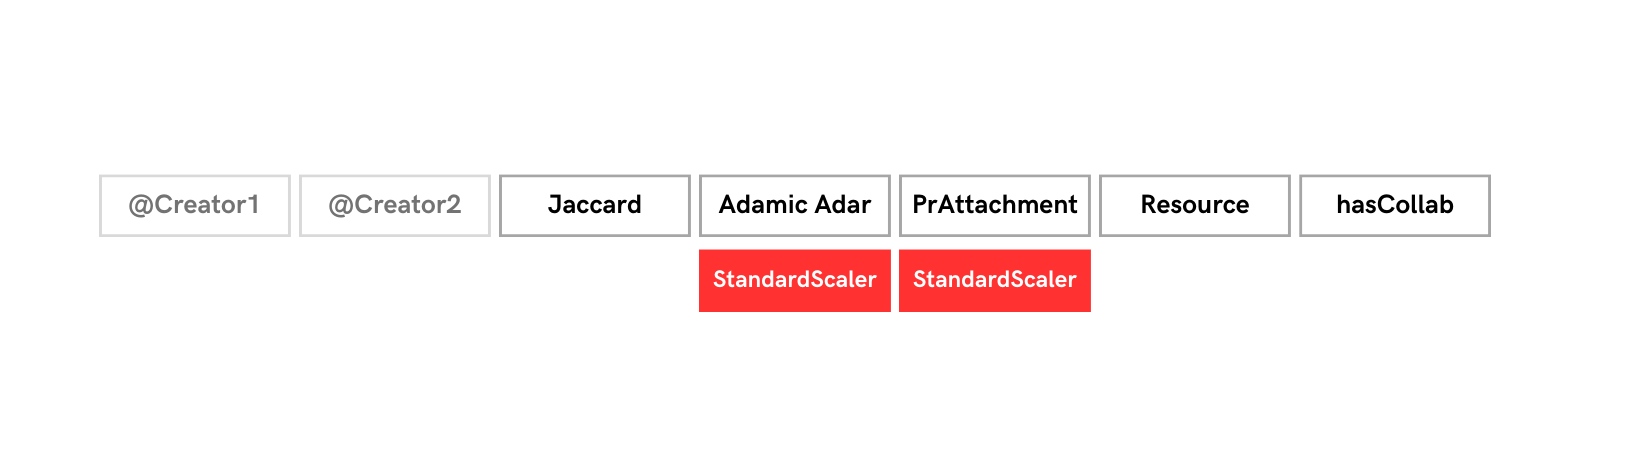

### Custom Transformer - Label Encoder
Non gestisce le nuove istanze di creators in modo nativo.

In [11]:
# Custom Transformer per Label Encoding
class LabelEncoderTransformer(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.labelEncoder = LabelEncoder()
        
    def fit(self, X, y=None):
        
        # Assicuro che X sia 1D
        X = np.ravel(X)
        
        self.labelEncoder.fit(X)
        
        return self
    
    def transform(self, X):
        
        # Assicuro che X sia 1D
        X = np.ravel(X)
        
        result = self.labelEncoder.transform(X)
        
        return result.reshape(-1, 1)
    
    def get_feature_names_out(self, input_features=None):
        return input_features

### Custom Transformer - RareCategoryCombiner
Utilizzato prima del OneHotEncoder per ridurre il numero di categorie create e il costo d'esecuzione.

In [12]:
# Custom Transformer per combinare categorie rare
class RareCategoryCombiner(BaseEstimator, TransformerMixin):
    
    def __init__(self, min_count = 10):
        
        self.min_count = min_count
        
    def fit(self, X, y=None):
        
        # Conta le occorrenze di ogni categoria
        self.category_counts = X.apply(pd.Series.value_counts)
        
        return self
    
    def transform(self, X):
        # Sostituisci le categorie rare con "other"
        return X.apply(lambda col: col.apply(lambda val: val if self.category_counts[col.name].get(val, 0) >= self.min_count else 'other'))
    
    def get_feature_names_out(self, input_features=None):
        return input_features

### Pipeline finale

In [13]:
# Pipeline
pipeline = Pipeline(
    [
         ('standardScaler', StandardScaler())
    ]
)

In [14]:
# Column Transformer
column_transformer = ColumnTransformer (

    transformers = [
        ('AdamicAdar', pipeline, ["AdamicAdar"]),
        ('PrAttachment', pipeline, ["PrAttachment"]),
    ],
    verbose_feature_names_out = True,
    remainder = 'passthrough',
    sparse_threshold = 0

)

### Fitting

In [15]:
# Separaro le Features dal Target nel TrainingSet


X = training_set.drop(columns=["creator1" ,"creator2", 'hasCollab'])

y = training_set['hasCollab']

creators = pd.concat([training_set["creator1"], training_set["creator2"]], axis=1)

In [16]:
# Preprocessing

X_transformed = column_transformer.fit(X)

print(X_transformed)

ColumnTransformer(remainder='passthrough', sparse_threshold=0,
                  transformers=[('AdamicAdar',
                                 Pipeline(steps=[('standardScaler',
                                                  StandardScaler())]),
                                 ['AdamicAdar']),
                                ('PrAttachment',
                                 Pipeline(steps=[('standardScaler',
                                                  StandardScaler())]),
                                 ['PrAttachment'])])


In [17]:
preproces_train_set = pd.DataFrame(column_transformer.transform(X), columns = column_transformer.get_feature_names_out())

print(preproces_train_set)

      AdamicAdar__AdamicAdar  PrAttachment__PrAttachment  remainder__Jaccard  \
0                        0.0                   -0.102088            0.000000   
1                        0.0                   -0.102088            0.000000   
2                        0.0                   -0.102088            0.000000   
3                        0.0                    8.815491            0.031452   
4                        0.0                   -0.102088            0.000000   
...                      ...                         ...                 ...   
7944                     0.0                   -0.102088            0.000185   
7945                     0.0                   -0.102088            0.000000   
7946                     0.0                   -0.102088            0.000000   
7947                     0.0                   -0.102088            0.000000   
7948                     0.0                   -0.102088            0.000000   

      remainder__Resource  
0          

## Classificazione - Random Forest
### Training
Random Forest (ensamble).
Con class_weight='balanced', il modello tratta i campioni delle classi minoritarie (Target = 1) come se fossero più importanti, aumentando il loro peso nella funzione di perdita utilizzata durante l'addestramento.

In [18]:
# predictor Random Forest

collab_predictor_RF = Pipeline([
    ('preprocessing', column_transformer),
    ('RandomForestClassifier',  RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42))
])

print(collab_predictor_RF)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough', sparse_threshold=0,
                                   transformers=[('AdamicAdar',
                                                  Pipeline(steps=[('standardScaler',
                                                                   StandardScaler())]),
                                                  ['AdamicAdar']),
                                                 ('PrAttachment',
                                                  Pipeline(steps=[('standardScaler',
                                                                   StandardScaler())]),
                                                  ['PrAttachment'])])),
                ('RandomForestClassifier',
                 RandomForestClassifier(class_weight='balanced',
                                        random_state=42))])


In [19]:
collab_predictor_RF.fit(X, y)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough', sparse_threshold=0,
                                   transformers=[('AdamicAdar',
                                                  Pipeline(steps=[('standardScaler',
                                                                   StandardScaler())]),
                                                  ['AdamicAdar']),
                                                 ('PrAttachment',
                                                  Pipeline(steps=[('standardScaler',
                                                                   StandardScaler())]),
                                                  ['PrAttachment'])])),
                ('RandomForestClassifier',
                 RandomForestClassifier(class_weight='balanced',
                                        random_state=42))])

### Testing

In [20]:
# Carico e visualizzo le info del Dataset
testing_set = pd.read_csv("Data/MLdataset_test.csv")

testing_set.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7950 entries, 0 to 7949
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   creator1      7950 non-null   object 
 1   creator2      7950 non-null   object 
 2   Jaccard       7950 non-null   float64
 3   AdamicAdar    7950 non-null   float64
 4   PrAttachment  7950 non-null   int64  
 5   Resource      7950 non-null   float64
 6   hasCollab     7950 non-null   int64  
dtypes: float64(3), int64(2), object(2)
memory usage: 434.9+ KB


In [21]:
# Separaro le Features dal Target nel Testingset

X_test = testing_set.drop(columns=["creator1" ,"creator2", 'hasCollab'])

y_test = testing_set['hasCollab']

creators_test = pd.concat([training_set["creator1"], training_set["creator2"]], axis=1)

In [22]:
#Predizione Test

y_test_predicted = collab_predictor_RF.predict(X_test)

## Valutazione delle Performance

### Confusion Matrix - Predizione sul Testing Set

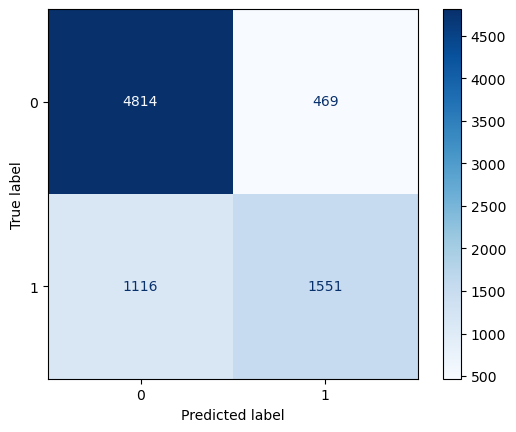

In [23]:
# Confusion Matrix

conf_matrix = confusion_matrix(y_test, y_test_predicted)
ConfusionMatrixDisplay.from_predictions(y_test, y_test_predicted, cmap=plt.cm.Blues)

### Confusion Matrix - Predizione sul Training Set

In [24]:
#Predizione Training

y_train_predicted = collab_predictor_RF.predict(X)

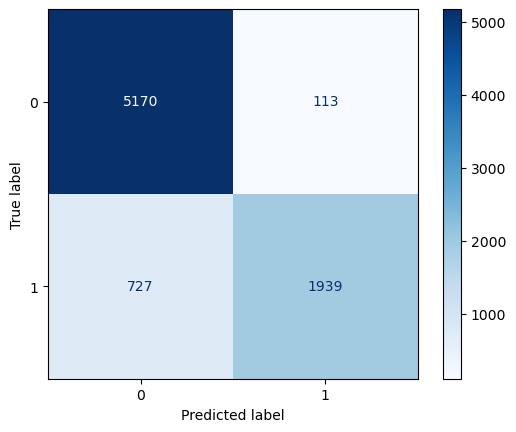

In [25]:
# Confusion Matrix

conf_matrix = confusion_matrix(y, y_train_predicted)
ConfusionMatrixDisplay.from_predictions(y, y_train_predicted, cmap=plt.cm.Blues)

### Accuracy

In [26]:
print(f" Test: {accuracy_score(y_test, y_test_predicted)} ; Train: {accuracy_score(y, y_train_predicted)}")

 Test: 0.8006289308176101 ; Train: 0.8943263303560196


### Recall

In [27]:
print(f"Test: {recall_score(y_test, y_test_predicted)} ; Train: {recall_score(y, y_train_predicted)}")

Test: 0.5815523059617548 ; Train: 0.7273068267066767


### Precision

In [28]:
print(f"Test: {precision_score(y_test, y_test_predicted)} ; Train: {precision_score(y, y_train_predicted)}")

Test: 0.7678217821782178 ; Train: 0.9449317738791423


### F1-score

In [29]:
print(f"Test: {f1_score(y_test, y_test_predicted)} ; Train: {f1_score(y, y_train_predicted)}")

Test: 0.6618305952634947 ; Train: 0.8219584569732937


## Trade-off

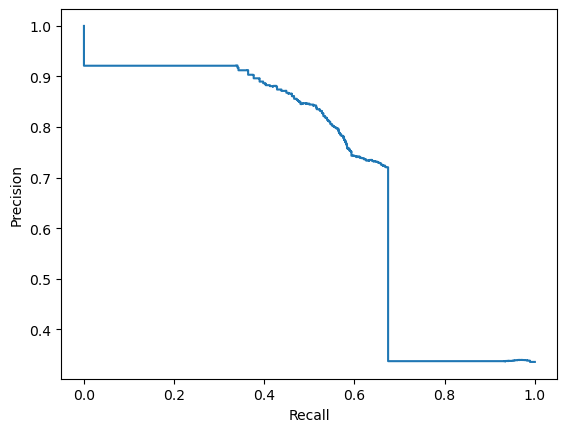

In [30]:
# Probabilità utilizzando il metodo predict_proba
y_proba = collab_predictor_RF.predict_proba(X_test)[:, 1]

# Calcolo precision e recall per tutte le soglie possibili
precision, recall, thresholds = precision_recall_curve(y_test, y_proba)

# Visualizza la curva precision-recall
disp = PrecisionRecallDisplay(precision=precision, recall=recall)
disp.plot()
plt.show()

In [31]:
# Trovo la soglia che ottimizza un trade-off specifico (ad esempio, F1-score)
f1_scores = 2 * (precision * recall) / (precision + recall)
best_index = f1_scores.argmax()
best_threshold = thresholds[best_index]

print(f'Soglia ottimale basata sul F1-Score: {best_threshold}')

Soglia ottimale basata sul F1-Score: 0.24


## Predizioni Finali

In [32]:
# Predizioni finali utilizzando la soglia trovata
y_pred_best = (y_proba >= best_threshold).astype(int)

In [33]:
# Metriche finali con la soglia ottimale
final_accuracy = accuracy_score(y_test, y_pred_best)
final_precision = precision_score(y_test, y_pred_best)
final_recall = recall_score(y_test, y_pred_best)
final_f1 = f1_score(y_test, y_pred_best)

print(f'Final Accuracy: {final_accuracy}')
print(f'Final Precision: {final_precision}')
print(f'Final Recall: {final_recall}')
print(f'Final F1 Score: {final_f1}')

Final Accuracy: 0.8030188679245283
Final Precision: 0.7204645574689628
Final Recall: 0.6745406824146981
Final F1 Score: 0.6967467079783114


### ROC-AUC

In [48]:
auc_score = roc_auc_score(y_test, y_proba)
print(f'ROC-AUC Score: {auc_score}')

ROC-AUC Score: 0.7752517590610655


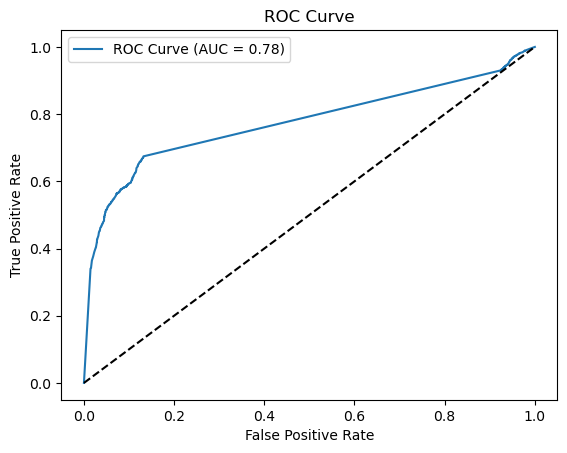

In [49]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc_score:.2f})')
plt.plot([0, 1], [0, 1], 'k--')  # Linea di riferimento
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='best')
plt.show()


## Classificazione - Logistic Regression

In [34]:
# predictor Logistic Regression

collab_predictor_LR = Pipeline([
    ('preprocessing', column_transformer),
    ('LogisticRegressionClassifier', LogisticRegression(penalty=None)
    )])

print(collab_predictor_LR)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough', sparse_threshold=0,
                                   transformers=[('AdamicAdar',
                                                  Pipeline(steps=[('standardScaler',
                                                                   StandardScaler())]),
                                                  ['AdamicAdar']),
                                                 ('PrAttachment',
                                                  Pipeline(steps=[('standardScaler',
                                                                   StandardScaler())]),
                                                  ['PrAttachment'])])),
                ('LogisticRegressionClassifier',
                 LogisticRegression(penalty=None))])


In [35]:
collab_predictor_LR.fit(X, y)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough', sparse_threshold=0,
                                   transformers=[('AdamicAdar',
                                                  Pipeline(steps=[('standardScaler',
                                                                   StandardScaler())]),
                                                  ['AdamicAdar']),
                                                 ('PrAttachment',
                                                  Pipeline(steps=[('standardScaler',
                                                                   StandardScaler())]),
                                                  ['PrAttachment'])])),
                ('LogisticRegressionClassifier',
                 LogisticRegression(penalty=None))])

### Testing

In [36]:
#Predizione Test

y_test_predicted = collab_predictor_LR.predict(X_test)

## Valutazione delle Performance

### Confusion Matrix - Predizione sul Testing Set

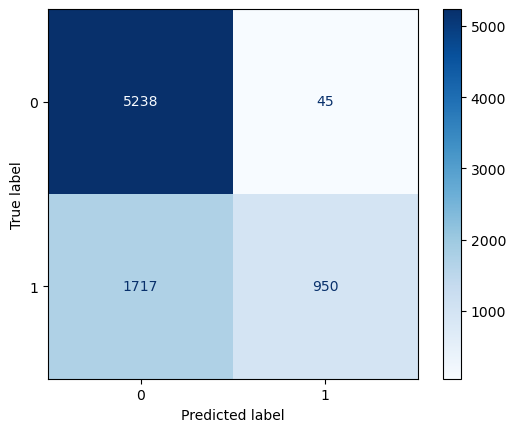

In [37]:
# Confusion Matrix

conf_matrix = confusion_matrix(y_test, y_test_predicted)
ConfusionMatrixDisplay.from_predictions(y_test, y_test_predicted, cmap=plt.cm.Blues)

### Confusion Matrix - Predizione sul Training Set

In [38]:
#Predizione Training

y_train_predicted = collab_predictor_LR.predict(X)

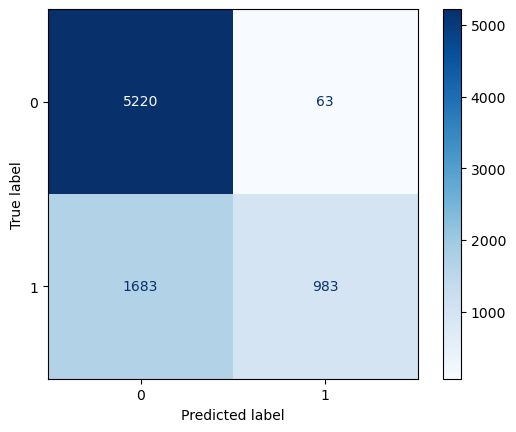

In [39]:
# Confusion Matrix

conf_matrix = confusion_matrix(y, y_train_predicted)
ConfusionMatrixDisplay.from_predictions(y, y_train_predicted, cmap=plt.cm.Blues)

### Accuracy

In [40]:
print(f" Test: {accuracy_score(y_test, y_test_predicted)} ; Train: {accuracy_score(y, y_train_predicted)}")

 Test: 0.7783647798742138 ; Train: 0.7803497295257265


### Recall

In [41]:
print(f"Test: {recall_score(y_test, y_test_predicted)} ; Train: {recall_score(y, y_train_predicted)}")

Test: 0.35620547431571054 ; Train: 0.3687171792948237


### Precision

In [42]:
print(f"Test: {precision_score(y_test, y_test_predicted)} ; Train: {precision_score(y, y_train_predicted)}")

Test: 0.9547738693467337 ; Train: 0.9397705544933078


### F1-Score

In [43]:
print(f"Test: {f1_score(y_test, y_test_predicted)} ; Train: {f1_score(y, y_train_predicted)}")

Test: 0.5188421627525942 ; Train: 0.5296336206896551
